# Fig 3 · Accuracy of Spindle, whole tiles and gene sets

**Run first:** `R0_index_cache` → `R2_whole_tile` (`results/whole_tile/nx.csv`) and `R3_gene_set`
(`results/gene_set/nx.csv`, `nx_size.csv`). Login node, spindle_env (the figure font); seconds.

Every method is graded against the ranking of Spindle-naive at c = 5 % of N: RDE (CSV column `NX5`) and
NNR(5 %, 5 % of N) (`overlap5`), mean ± s.d. over seeds 0–4.
* **A** Spindle per dataset: whole-tile search (g = 0.25) and gene-set search (all gene-set sizes pooled); RDE left,
  NNR right.
* **B** RDE of gene-set search against |S|: Spindle, and the query completed to all genes by padding or imputation
  and searched with Spindle-naive (median over datasets).
* **C** NNR of the same against |S|.

The typical-query distance distributions and memory against fidelity are appendix material
(`experiments/figures/_backup_2026-11-01/`).

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import pandas as pd
from matplotlib.lines import Line2D

import style as ps

FIG = "fig3_accuracy"
KEYS = ps.DATASET_ORDER
G = 0.25
SPINDLE, SPINDLE_GS = ps.TIER_COLORS["spindle"], ps.TIER_COLORS["spindle_partial"]
BASE = {"padding": "#44AA99", "imputation": "#882255"}
METHOD_LABEL = {"spindle_partial": "Spindle (gene sets)", "padding": "Padding + Spindle-naive",
                "imputation": "Imputation + Spindle-naive"}
MARK = {"spindle_partial": "^", "padding": "s", "imputation": "o"}
COLOR = {"spindle_partial": SPINDLE_GS, **BASE}
W_A, W_B, W_C, H = 70.0, 55.0, 55.0, 58.0
TOP, BOTTOM = 3.0, 10.0              # mm above / below the axes, shared by the three panels
LEG_H = 8.0
OFF = 0.17                           # whole tile above, gene sets below, in a dataset's row

whole = pd.read_csv(ROOT / "results" / "whole_tile" / "nx.csv")
whole = whole[whole.g == G].set_index("key")
gene = pd.read_csv(ROOT / "results" / "gene_set" / "nx.csv")
gene = gene[(gene.method == "spindle_partial") & (gene["size"] == 0)].set_index("key")
nx_size = pd.read_csv(ROOT / "results" / "gene_set" / "nx_size.csv")
print(sorted(set(whole.tag) | set(gene.tag) | set(nx_size.tag)))


def rows_axis(ax, labels):
    ax.set_ylim(len(KEYS) - 0.5, -0.5)
    ax.set_yticks(range(len(KEYS)))
    ax.set_yticklabels([ps.DATASET_LABELS[k] for k in KEYS] if labels else [])
    ax.tick_params(axis="y", length=0)

['method-v2']


## A · Spindle per dataset: RDE and NNR, whole tiles and gene sets

figures/fig3_accuracy/panels/A.pdf/.png: 70 x 58 mm, 0.0 / 0.2 MB


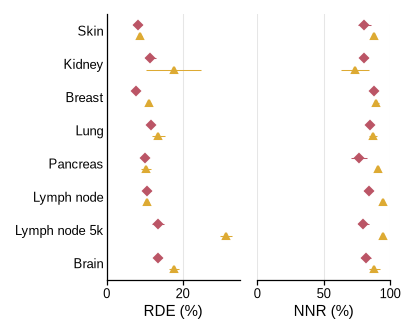

In [2]:
def panel_a(fig):
    W, _ = ps.size_mm(fig)
    left = 19.0
    w = (W - left) / 2
    for j, (col, xlabel, xlim) in enumerate((("NX5", "RDE (%)", (0, 35)), ("overlap5", "NNR (%)", (0, 100)))):
        ax = ps.axes(fig, left=left + j * w, right=W - left - (j + 1) * w + 3.0, bottom=BOTTOM, top=TOP)
        for t, dy, c, mk in ((whole, -OFF, SPINDLE, "D"), (gene, OFF, SPINDLE_GS, "^")):
            for i, k in enumerate(KEYS):
                r = t.loc[k]
                ax.errorbar(100 * r[col], i + dy, xerr=100 * r[f"{col}_sd"], fmt=mk, ms=2.8, color=c,
                            elinewidth=0.5, zorder=3)
        rows_axis(ax, j == 0)
        ax.set_xlim(*xlim)
        ax.grid(True, axis="x", color="#E6E6E6", linewidth=0.5, zorder=0)
        ax.set_axisbelow(True)
        ax.set_xlabel(xlabel)
        if j:
            ax.spines["left"].set_visible(False)


fig = ps.panel(W_A, H)
panel_a(fig)
ps.save_panel(fig, FIG, "A")

## B, C · Gene sets: RDE and NNR against |S|, Spindle against padding and imputation

figures/fig3_accuracy/panels/B.pdf/.png: 55 x 58 mm, 0.0 / 0.2 MB
figures/fig3_accuracy/panels/C.pdf/.png: 55 x 58 mm, 0.0 / 0.2 MB


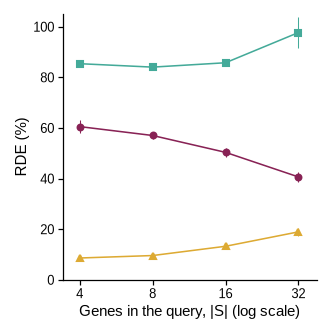

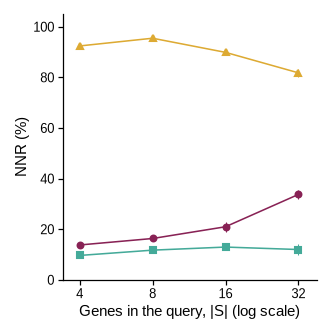

In [3]:
def by_size(fig, col, ylabel):
    ax = ps.axes(fig, left=10.0, right=2.0, bottom=BOTTOM, top=TOP)
    t = nx_size[nx_size["size"] > 0]
    for m in ("padding", "imputation", "spindle_partial"):
        s = t[t.method == m].sort_values("size")
        ax.errorbar(s["size"], 100 * s[col], yerr=100 * s[f"{col}_sd"], fmt=f"-{MARK[m]}", ms=2.8, color=COLOR[m],
                    elinewidth=0.5, zorder=3 if m == "spindle_partial" else 2)
    ax.set_xscale("log", base=2)
    ax.set_xticks([4, 8, 16, 32], ["4", "8", "16", "32"])
    ax.minorticks_off()
    ax.set_xlim(3.4, 38)
    ax.set_ylim(0, 105)
    ax.set_xlabel("Genes in the query, |S| (log scale)")
    ax.set_ylabel(ylabel)


def panel_b(fig):
    by_size(fig, "NX5", "RDE (%)")


def panel_c(fig):
    by_size(fig, "overlap5", "NNR (%)")


fig = ps.panel(W_B, H)
panel_b(fig)
ps.save_panel(fig, FIG, "B")
fig = ps.panel(W_C, H)
panel_c(fig)
ps.save_panel(fig, FIG, "C")

## Legend and full figure

figures/fig3_accuracy/panels/legend.pdf/.png: 180 x 8 mm, 0.0 / 0.1 MB
figures/fig3_accuracy/fig3_accuracy.pdf/.png: 180 x 66 mm, 0.0 / 0.6 MB


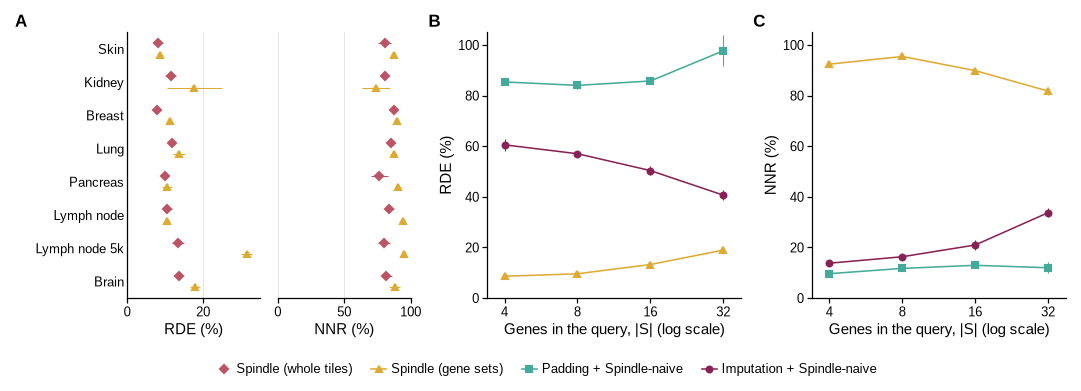

<Figure size 1062.99x47.2441 with 0 Axes>

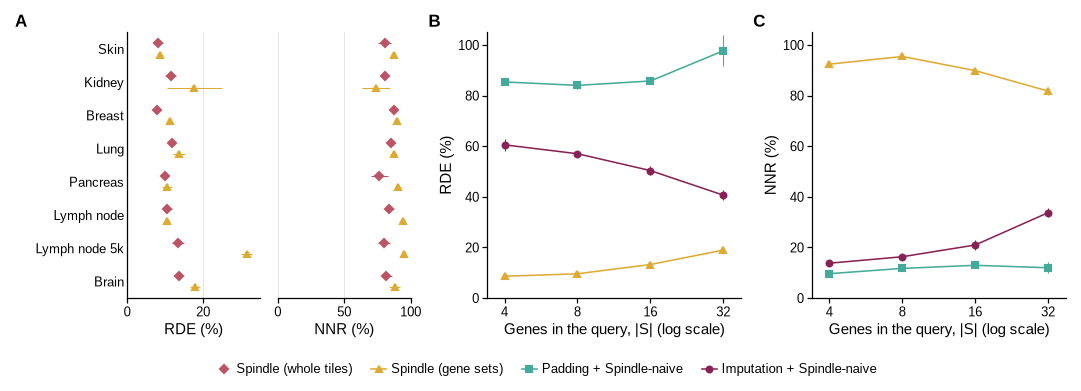

In [4]:
HANDLES = ([Line2D([], [], ls="", marker="D", ms=2.8, color=SPINDLE, label="Spindle (whole tiles)")]
           + [Line2D([], [], marker=MARK[m], ms=2.8, color=COLOR[m], label=METHOD_LABEL[m])
              for m in ("spindle_partial", "padding", "imputation")])


def legend(fig):
    fig.legend(handles=HANDLES, ncol=4, loc="upper center", columnspacing=1.5)


fig = ps.panel(180, LEG_H); legend(fig); ps.save_panel(fig, FIG, "legend")

page = ps.page(180, H + LEG_H)
panel_a(ps.place(page, "A", 0, 0, W_A, H))
panel_b(ps.place(page, "B", W_A, 0, W_B, H))
panel_c(ps.place(page, "C", W_A + W_B, 0, W_C, H))
legend(ps.place(page, None, 0, H + 1.0, 180, LEG_H - 1.0))
ps.save_figure(page, FIG)
page